# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

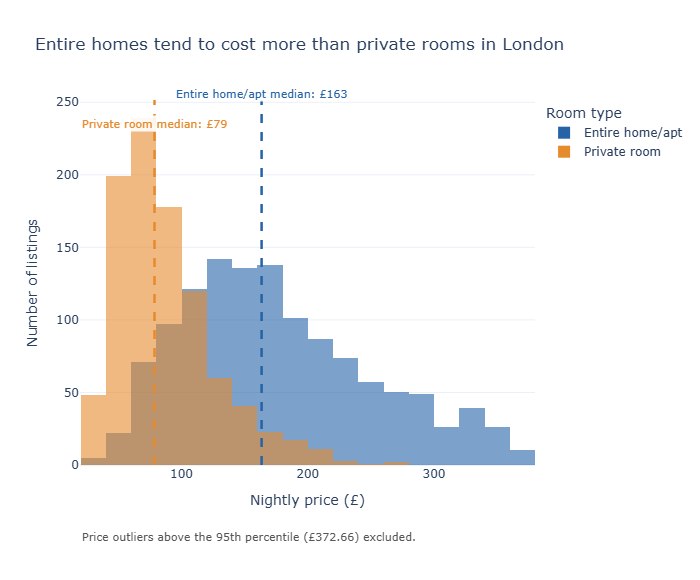

In [4]:
# Task 1 — Overlaid histograms: Entire home/apt vs Private room
room_types = ['Entire home/apt', 'Private room']
price_data = df_cap.loc[df_cap['room_type'].isin(room_types)].copy()
colors = {'Entire home/apt': '#2563A6', 'Private room': '#E68A2E'}
medians = price_data.groupby('room_type')['price'].median()

fig1 = px.histogram(
    price_data,
    x='price',
    color='room_type',
    color_discrete_map=colors,
    category_orders={'room_type': room_types},
    nbins=35,
    barmode='overlay',
    opacity=0.6,
    labels={'price': 'Nightly price (£)', 'count': 'Number of listings', 'room_type': 'Room type'},
    title='Entire homes tend to cost more than private rooms in London'
)

# Separate median reference lines, matched to each distribution's colour.
for room_type in room_types:
    median = medians[room_type]
    fig1.add_vline(
        x=median,
        line_color=colors[room_type],
        line_width=2.5,
        line_dash='dash'
    )
    fig1.add_annotation(
        x=median,
        y=1.04 if room_type == 'Entire home/apt' else 0.96,
        xref='x', yref='paper',
        text=f'{room_type} median: £{median:.0f}',
        showarrow=False,
        font=dict(color=colors[room_type], size=11),
        bgcolor='rgba(255,255,255,0.9)'
    )

fig1.add_annotation(
    x=0, y=-0.22, xref='paper', yref='paper',
    text=f'Price outliers above the 95th percentile (£{p95:.2f}) excluded.',
    showarrow=False, xanchor='left', font=dict(size=11, color='#555555')
)
fig1.update_layout(
    template='plotly_white',
    xaxis_title='Nightly price (£)',
    yaxis_title='Number of listings',
    legend_title_text='Room type',
    margin=dict(t=100, b=115),
    height=580
)
fig1.show(renderer='png')

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

In [7]:
import plotly.graph_objects as go
# Task 2 — Horizontal box plots: reviews per month by London borough
# Zero or missing review rates are excluded (new or inactive listings).
activity = df.loc[df['reviews_per_month'].notna() & (df['reviews_per_month'] > 0)].copy()
borough_medians = (
    activity.groupby('neighbourhood')['reviews_per_month']
    .median()
    .sort_values(ascending=False)
)
top_two = borough_medians.head(2).index.tolist()
borough_order = borough_medians.index.tolist()
overall_median = activity['reviews_per_month'].median()

# One box per borough makes it possible to highlight exactly two boroughs.
fig2 = go.Figure()
for borough in borough_order:
    values = activity.loc[activity['neighbourhood'] == borough, 'reviews_per_month']
    highlighted = borough in top_two
    fig2.add_trace(go.Box(
        x=values,
        y=[borough] * len(values),
        name=borough,
        orientation='h',
        marker=dict(color='#E68A2E' if highlighted else '#B9BDC5', size=4),
        line=dict(color='#C56A10' if highlighted else '#777D87'),
        fillcolor='rgba(230,138,46,0.45)' if highlighted else 'rgba(185,189,197,0.45)',
        boxpoints='outliers',
        showlegend=False,
        hovertemplate=f'{borough}<br>Reviews/month: %{{x:.2f}}<extra></extra>'
    ))

# Global median reference line and explanatory annotation.
fig2.add_vline(x=overall_median, line_color='#245C96', line_dash='dash', line_width=2)
fig2.add_annotation(
    x=overall_median, y=1.035, xref='x', yref='paper',
    text=f'Overall median: {overall_median:.2f} reviews/month',
    showarrow=False, font=dict(color='#245C96', size=11),
    bgcolor='rgba(255,255,255,0.9)'
)
fig2.update_layout(
    title=f'{top_two[0]} and {top_two[1]} lead in median review activity',
    xaxis_title='Reviews per month (proxy for listing activity)',
    yaxis_title='London borough',
    template='plotly_white',
    height=max(650, 32 * len(borough_order) + 150),
    margin=dict(l=190, r=45, t=100, b=65)
)
# Show highest-median borough at the top.
fig2.update_yaxes(
    categoryorder='array',
    categoryarray=borough_order[::-1]
)
fig2.show(rendered='png')
print('Top two boroughs by median reviews per month:')
print(borough_medians.head(2).round(2).to_string())
print(f'Overall median (positive reviews only): {overall_median:.2f}')

Top two boroughs by median reviews per month:
neighbourhood
Tower Hamlets    1.75
Hackney          1.66
Overall median (positive reviews only): 1.43
